In [1]:
# The first time only: install TensorFlow (Keras comes with it)
# Then click "Restart" (the kernel) and run the notebook from the top.
%pip install tensorflow==2.21.0

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'D:\MLOps_Project\venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide the TensorFlow info messages

import pickle
from glob import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa

from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

import keras
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.optimizers import Adam

import mlflow
import mlflow.keras

In [3]:
# my folders (the same as in the other notebooks)
project_folder = "D:/MLOps_Project/"
ourdataset_folder = "D:/MLOps_Project/ourdataset/train/"
plots_folder = "D:/MLOps_Project/models plots/"    # the figures of the notebooks (saved here, then sent to MLflow)


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)


def save_data(data, file_name):
    with open(file_name, "wb") as f:
        pickle.dump(data, f)

In [4]:
# ==================== From a wav to a Mel spectrogram (the "image" of the sound) ====================
SR = 2000        # every wav at 2000 Hz (like in the project: heart sounds are below 1000 Hz)
SECONDS = 5      # every wav = 5 seconds, because the CNN needs images of the same size


def get_spectrogram(file):
    signal, rate = librosa.load(file, sr=SR)

    # skip the broken wavs (the same rules as TP3 and TP4)
    too_short = len(signal) < 2 * SR                       # less than 2 seconds
    silent = np.max(np.abs(signal)) < 0.001                # almost no sound
    saturated = np.mean(np.abs(signal) >= 0.99) > 0.01     # more than 1% of the samples at the maximum
    if too_short or silent or saturated:
        return None

    # the same size for every wav: we keep the middle 5 seconds (a shorter wav is repeated)
    n = SR * SECONDS                                       # 10000 samples
    if len(signal) < n:
        signal = np.tile(signal, n // len(signal) + 1)[:n]
    else:
        start = (len(signal) - n) // 2
        signal = signal[start:start + n]

    # the Mel spectrogram in dB (course 2): 40 mel bands x 157 moments
    S = librosa.feature.melspectrogram(y=signal, sr=rate, n_fft=256, hop_length=64, n_mels=40)
    S_DB = librosa.power_to_db(S, ref=np.max)
    return S_DB

In [5]:
# reads all the wavs (a few minutes): run it once, after that the 2 .data files are enough
spectrograms = []
labels = []
for class_name in ["abnormal", "normal"]:
    for file in glob(ourdataset_folder + class_name + "/*.wav"):
        S_DB = get_spectrogram(file)
        if S_DB is None:          # broken wav -> we skip it
            continue
        spectrograms.append(S_DB)
        if class_name == "abnormal":
            labels.append(1)
        else:
            labels.append(0)

save_data(spectrograms, project_folder + "cnn_spectrograms.data")
save_data(labels, project_folder + "cnn_labels.data")
print(len(spectrograms), "spectrograms of size", spectrograms[0].shape)

3681 spectrograms of size (40, 157)


X: (3681, 40, 157, 1) | normal: 2855 | abnormal: 826


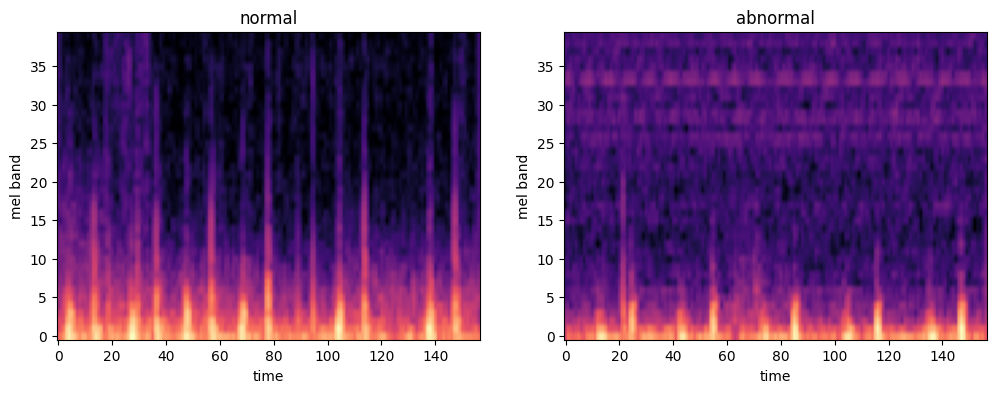

In [6]:
spectrograms = load_data(project_folder + "cnn_spectrograms.data")
labels = load_data(project_folder + "cnn_labels.data")

X = np.array(spectrograms)     # (number of wavs, 40, 157)
y = np.array(labels)           # 1 = abnormal, 0 = normal

X = (X + 80) / 80              # dB from -80 to 0 -> numbers from 0 to 1 (like dividing the pixels by 255 in the course)
X = X.reshape(X.shape[0], 40, 157, 1)    # add 1 channel at the end, like a grey image

print("X:", X.shape, "| normal:", np.sum(y == 0), "| abnormal:", np.sum(y == 1))

# what the CNN sees: 1 normal and 1 abnormal spectrogram
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(X[y == 0][0, :, :, 0], aspect="auto", origin="lower", cmap="magma")
plt.title("normal")
plt.xlabel("time")
plt.ylabel("mel band")
plt.subplot(1, 2, 2)
plt.imshow(X[y == 1][0, :, :, 0], aspect="auto", origin="lower", cmap="magma")
plt.title("abnormal")
plt.xlabel("time")
plt.ylabel("mel band")
plt.show()

In [7]:
# ==================== Our CNN ====================
def build_cnn():
    model = Sequential()
    model.add(Input(shape=(40, 157, 1)))         # 1 spectrogram = a grey image of 40 x 157

    # block 1: 16 filters of 3x3 look for small patterns (like the vertical line detector of the course)
    model.add(Conv2D(16, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2)))              # keeps the max of each 2x2 square: the image becomes 2x smaller

    # block 2: 32 filters, they combine the patterns found by block 1
    model.add(Conv2D(32, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2)))

    # block 3: 64 filters
    model.add(Conv2D(64, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2)))

    model.add(Flatten())                         # the feature maps become 1 long vector
    model.add(Dense(32, activation="relu"))      # a fully connected layer (a classic neural network)
    model.add(Dropout(0.5))                      # switches off 50% of the neurons while training -> less overfitting
    model.add(Dense(1, activation="sigmoid"))    # 1 neuron: the probability that the heart is abnormal

    # Adam = the optimizer (it changes the weights), binary cross-entropy = the loss for 2 classes
    model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])
    return model


build_cnn().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 38, 155, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 77, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 17, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 37, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 35, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 17, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3264)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       104,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 127,809 (499.25 KB)

 Trainable params: 127,809 (499.25 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# like plot_acc_loss(): accuracy and loss after each epoch, train vs validation
def plot_acc_loss(history, fold):
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="train")
    plt.plot(history.history["val_accuracy"], label="validation")
    plt.title("Fold " + str(fold) + " - accuracy")
    plt.xlabel("epoch")
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="validation")
    plt.title("Fold " + str(fold) + " - loss")
    plt.xlabel("epoch")
    plt.legend()
    plt.savefig(plots_folder + "tp7_cnn_fold" + str(fold) + ".png")
    plt.show()

==================== Fold 1


[[618 319]
 [  7 283]]
              precision    recall  f1-score   support

      normal       0.99      0.66      0.79       937
    abnormal       0.47      0.98      0.63       290

    accuracy                           0.73      1227
   macro avg       0.73      0.82      0.71      1227
weighted avg       0.87      0.73      0.75      1227



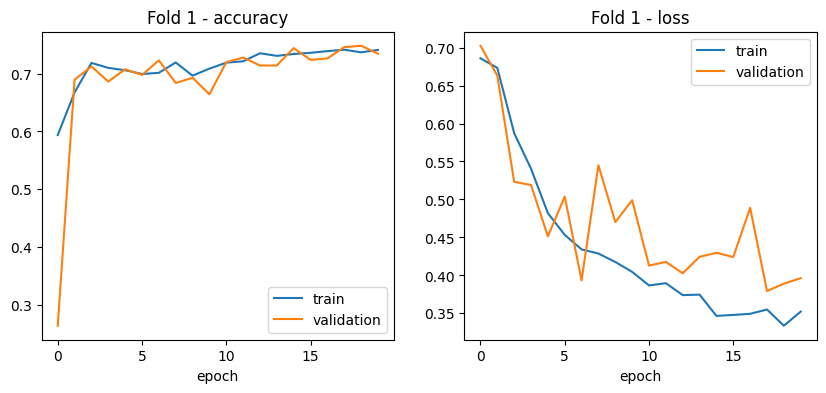

==================== Fold 2


[[697 265]
 [ 13 252]]
              precision    recall  f1-score   support

      normal       0.98      0.72      0.83       962
    abnormal       0.49      0.95      0.64       265

    accuracy                           0.77      1227
   macro avg       0.73      0.84      0.74      1227
weighted avg       0.87      0.77      0.79      1227



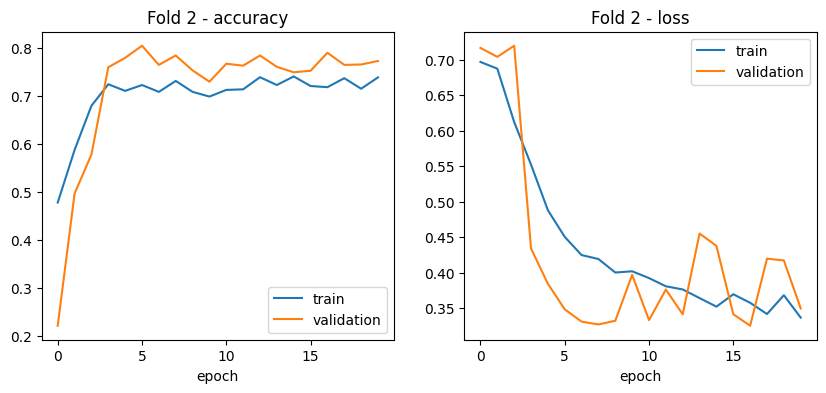

==================== Fold 3


[[785 171]
 [ 41 230]]
              precision    recall  f1-score   support

      normal       0.95      0.82      0.88       956
    abnormal       0.57      0.85      0.68       271

    accuracy                           0.83      1227
   macro avg       0.76      0.83      0.78      1227
weighted avg       0.87      0.83      0.84      1227



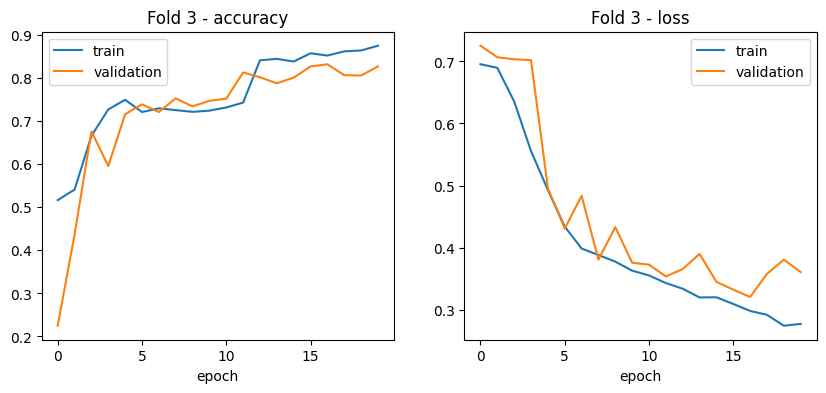

In [9]:
# ==================== Training and testing on 3 folds (like TP3) ====================
EPOCHS = 20         # 20 passes over the train wavs
BATCH_SIZE = 32     # the weights change after every 32 wavs

# we have 3.5x less abnormal wavs, so each abnormal wav counts 3.5x more (like class_weight="balanced" in TP3)
class_weight = {0: len(y) / (2 * np.sum(y == 0)), 1: len(y) / (2 * np.sum(y == 1))}

kfold = KFold(n_splits=3, shuffle=True, random_state=1)    # the same 3 folds as TP3 and TP4
results = []
histories = []      # the Keras history of each fold (its curves), kept for MLflow
fold = 1
for train_index, test_index in kfold.split(X):
    print("==================== Fold", fold)
    X_train, X_test = X[train_index], X[test_index]        # 2/3 of the wavs to train, 1/3 to test
    y_train, y_test = y[train_index], y[test_index]

    keras.utils.set_random_seed(0)      # the same random start each time -> the same results if we run it again
    model = build_cnn()
    history = model.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight,
                        validation_data=(X_test, y_test), verbose=0)
    # validation_data: the CNN does NOT learn from the test wavs, they are only used to draw the "validation" curves
    # verbose=0: nothing is printed while it trains (a minute or two per fold), the curves show every epoch

    # the sigmoid gives a probability: more than 0.5 -> abnormal (1), else normal (0)
    y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()

    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=["normal", "abnormal"]))
    results.append({
        "fold": fold,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),    # precision, recall, f1: of the abnormal class
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
    })
    plot_acc_loss(history, fold)
    histories.append(history)
    fold = fold + 1

In [10]:
table = pd.DataFrame(results)
print(table.round(3))
print()
print("Mean of the 3 folds:")
print(table[["accuracy", "precision", "recall", "f1"]].mean().round(3))

   fold  accuracy  precision  recall     f1
0     1     0.734      0.470   0.976  0.635
1     2     0.773      0.487   0.951  0.645
2     3     0.827      0.574   0.849  0.685

Mean of the 3 folds:
accuracy     0.778
precision    0.510
recall       0.925
f1           0.655
dtype: float64


In [11]:
# the 3 folds only MEASURE our CNN. The CNN we keep (in MLflow) learns from ALL the wavs
keras.utils.set_random_seed(0)
final_model = build_cnn()
final_model.fit(X, y, epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight, verbose=0)
print("final CNN trained on", len(y), "wavs")

final CNN trained on 3681 wavs


In [12]:
# ==================== MLflow (Service 6) ====================
# the MLflow container must be running: docker start mlflow-server
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark")       # the same experiment as the SVM and the decision tree

with mlflow.start_run(run_name="cnn"):
    mlflow.log_param("model", "CNN")
    mlflow.log_param("features", "mel spectrogram 40 x 157 (5 s, 2000 Hz)")
    mlflow.log_param("layers", "3 x (Conv2D + MaxPooling) + Flatten + Dense 32 + Dropout 0.5 + Dense 1")
    mlflow.log_param("optimizer", "adam")
    mlflow.log_param("learning_rate", 0.001)
    mlflow.log_param("epochs", EPOCHS)
    mlflow.log_param("batch_size", BATCH_SIZE)
    mlflow.log_param("n_folds", 3)

    for metric in ["accuracy", "precision", "recall", "f1"]:
        mlflow.log_metric("mean_" + metric, table[metric].mean())    # the mean of the 3 folds
    for r in results:    # the results of each fold, also here: fold1_accuracy, fold1_precision, ..., fold3_f1
        for metric in ["accuracy", "precision", "recall", "f1"]:
            mlflow.log_metric("fold" + str(r["fold"]) + "_" + metric, r[metric])

    for fold in [1, 2, 3]:
        mlflow.log_artifact(plots_folder + "tp7_cnn_fold" + str(fold) + ".png")    # the curves

    mlflow.keras.log_model(final_model, "model")    # the final CNN

    # the 3 folds: 1 small run per fold INSIDE the "cnn" run (nested=True), with its curves and its results
    for r in results:
        fold = r["fold"]
        h = histories[fold - 1].history    # what Keras saved after each epoch of this fold
        with mlflow.start_run(run_name="cnn_fold" + str(fold), nested=True):
            mlflow.log_param("fold", fold)
            # training vs validation: 1 point per epoch -> MLflow draws the curves (tab "Model metrics")
            for epoch in range(EPOCHS):
                mlflow.log_metric("train_loss", h["loss"][epoch], step=epoch + 1)
                mlflow.log_metric("val_loss", h["val_loss"][epoch], step=epoch + 1)
                mlflow.log_metric("train_accuracy", h["accuracy"][epoch], step=epoch + 1)
                mlflow.log_metric("val_accuracy", h["val_accuracy"][epoch], step=epoch + 1)
            # the results on the validation wavs of this fold (val_accuracy = the last point of its curve)
            mlflow.log_metric("val_precision", r["precision"])
            mlflow.log_metric("val_recall", r["recall"])
            mlflow.log_metric("val_f1", r["f1"])
            mlflow.log_artifact(plots_folder + "tp7_cnn_fold" + str(fold) + ".png")    # the figure of this fold

2026/11/22 17:58:46 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


2026/11/22 17:59:05 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


🏃 View run cnn_fold1 at: http://localhost:5000/#/experiments/1/runs/1144adf56331451698290bc2e798fa2f
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run cnn_fold2 at: http://localhost:5000/#/experiments/1/runs/b1d79091863b40b1a060c620493d2835
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run cnn_fold3 at: http://localhost:5000/#/experiments/1/runs/44b18e9a677943a581fafe1750727ce2
🧪 View experiment at: http://localhost:5000/#/experiments/1


🏃 View run cnn at: http://localhost:5000/#/experiments/1/runs/6516808df9834234a5f069a2f472ccc1
🧪 View experiment at: http://localhost:5000/#/experiments/1
